+--------------------------------------------------------------------+
| Configuration for experiment     train_model_2026-10-30_03-17-33   |
+--------------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator             |
| Scheduler                        FIFOScheduler                     |
| Number of trials                 10                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/train_model_2026-10-30_03-17-33
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2026-10-30_03-04-02_184535_2644/artifacts/2026-10-30_03-17-33/train_model_2026-10-30_03-17-33/driver_artifacts`

Best Hyperparameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 5}
Best Validation Accuracy: 98.82 %
Final Test Accuracy: 88.37 %

Classification Report:
              precision    recall  f1-score   suppor

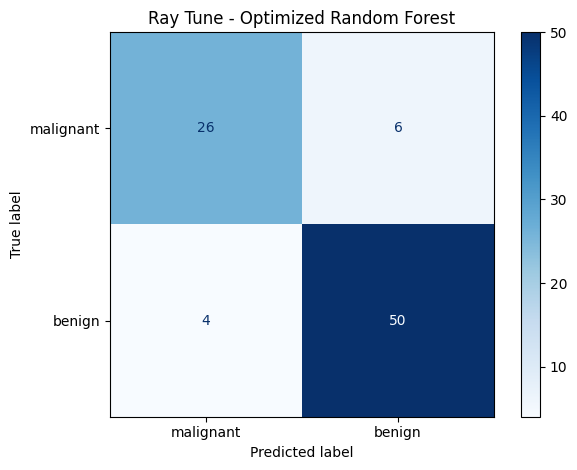

In [7]:
!pip install -q "ray[tune]"

import ray
from ray import tune
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split data into training, validation and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# Training function for Ray Tune
def train_model(config):
    model = RandomForestClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        min_samples_split=config["min_samples_split"],
        random_state=42,
        n_jobs=-1)
    model.fit(X_train, y_train)
    accuracy = accuracy_score(y_val, model.predict(X_val))
    tune.report({"accuracy": accuracy})

# Hyperparameter search space
search_space = {
    "n_estimators": tune.choice([50, 100, 150, 200]),
    "max_depth": tune.choice([5, 10, 15, 20, None]),
    "min_samples_split": tune.choice([2, 5, 10])}

# Run Ray Tune
results = tune.run(
    train_model,
    config=search_space,
    metric="accuracy",
    mode="max",
    num_samples=10,
    verbose=0)

# Train best model
best_params = results.best_config
model = RandomForestClassifier(
    **best_params, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Test evaluation
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Display results
print("Best Hyperparameters:", best_params)
print("Best Validation Accuracy:", round(results.best_result["accuracy"] * 100, 2), "%")
print("Final Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names, digits=3))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=data.target_names,
    cmap="Blues",
    values_format="d")
plt.title("Ray Tune - Optimized Random Forest")
plt.tight_layout()
plt.show()